# Lab Assignment 3 - Scientific Computing Lab

## Submitted by - Naman Jain, SC26M013

0.3320573257128654
1.0


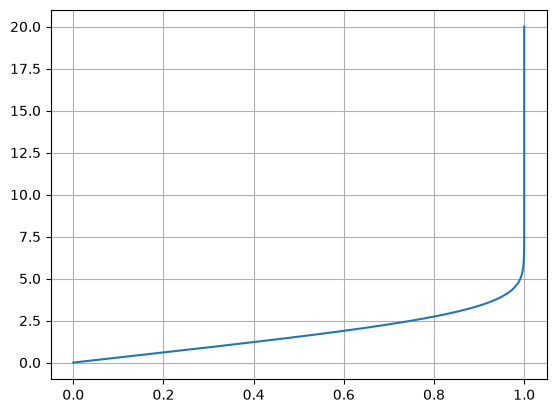

In [138]:
import numpy as np
import matplotlib.pyplot as plt

eta_inf = 20
h = 0.025

def first_order(u1, u2, u3):
    Y = np.array([u1, u2, u3])
    G = np.array([[0, 1, 0],[0, 0, 1],[0, 0, -u1/2]])

    Y_d = G @ Y
    return Y_d

def RK3(s,h, eta_inf):
    
    N = int(eta_inf / h)
    Y = np.zeros((N + 1, 3))
    eta = np.linspace(0, eta_inf, N + 1)

    Y[0, 0] = 0
    Y[0, 1] = 0 
    Y[0, 2] = s
    
    for i in range(N):
        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])
        K2 = h * first_order(Y[i, 0] + K1[0]/2, Y[i, 1] + K1[1]/2, Y[i, 2] + K1[2]/2)
        K3 = h * first_order(Y[i, 0] - K1[0] + 2*K2[0], Y[i, 1] - K1[1] + 2*K2[1], Y[i, 2] - K1[2] + 2*K2[2])

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 4*K2[0] + K3[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 4*K2[1] + K3[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 4*K2[2] + K3[2])/6

    err = Y[-1, 1] - 1

    return eta, Y, err

def error(s, h):
    error = RK3(s, h, eta_inf)[2]
    return error 

def bisection(sl, su, eps, h):
    while (su - sl)/2 > eps:
        s = (su + sl)/2
        if error(s, h) == 0:
            return s 
            
        if error(sl, h)*error(s, h) < 0:
            su = s
        else:
            sl = s
    return s 

sl = 0
su = 1
eps = 1e-20

eta, Y, err1 = RK3(bisection(sl, su, eps, h), h, eta_inf)

print(bisection(sl, su, eps, h))
print(Y[-1,1])
plt.plot(Y[:, 1], eta)
plt.grid(True)
plt.show()

In [139]:
h_values = [0.4, 0.2, 0.1, 0.05, 0.025]
sl = 0
su = 0.5
eps = 1e-20
s_value = np.zeros(len(h_values))
error_values = np.zeros(len(h_values))

for i, hi in enumerate(h_values):
    s_value[i] = bisection(sl, su, eps, hi)
    eta, Y, err = RK3(s_value[i], hi, eta_inf)
    
    s_exact = 0.3320573362
    error_values[i] = np.abs(s_value[i] - s_exact)

print('Shooting Values s: ', s_value)
print('Error Values:', error_values)

Shooting Values s:  [0.33197714 0.3320496  0.33205653 0.33205725 0.33205733]
Error Values: [8.01914287e-05 7.73869388e-06 8.03761523e-07 8.95936970e-08
 1.04871346e-08]


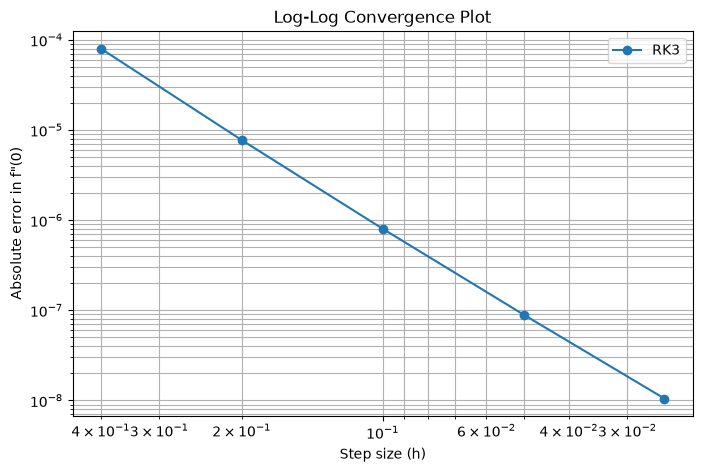

Order of Accuracy:  [3.37328605 3.26725067 3.16529837 3.0947767 ]


In [140]:
order = np.zeros(len(h_values) - 1)

for i in range(len(h_values) - 1):
    order[i] = np.log(error_values[i]/error_values[i + 1])/np.log(h_values[i]/h_values[i + 1])

plt.figure(figsize=(8,5))
plt.loglog(h_values, error_values, 'o-', label='RK3')
plt.xlabel('Step size (h)')
plt.ylabel('Absolute error in f"(0)')
plt.title('Log-Log Convergence Plot')
plt.grid(True, which='both')
plt.legend()
plt.gca().invert_xaxis()
plt.show()

print("Order of Accuracy: ", order)